# TransGeo — Fine-Tuned Model Evaluation

This notebook is **evaluation only**. It loads the fine-tuned TransGeo checkpoint and applies the same external test design used for Sample4Geo.

## Outputs

For the fine-tuned TransGeo weight it generates:

1. **Four similarity matrices**
   - Positive
   - Easy Negative
   - Random Negative
   - Hard Negative

2. **Positive confusion matrix**
   - actual positive = filename-matched ground/satellite pair
   - predicted positive = cosine similarity > 0.50

3. **Negative FPR table**
   - Easy Negative
   - Random Negative
   - Hard Negative
   - every pair in these three sets is an actual negative
   - cosine similarity > 0.50 is therefore a false positive

The existing ground-image folders and satellite-image filenames are reused unchanged.

# 1. Configuration

The friend's fine-tuning notebook used the CVIAN TransGeo configuration with:

- ground input: **112 × 616**
- satellite input: **256 × 256**
- embedding dimension: **1000**
- ImageNet normalization

The evaluation notebook reconstructs the same TransGeo architecture and loads the saved `state_dict`.

In [4]:
from pathlib import Path
from types import SimpleNamespace
import sys
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from IPython.display import display

import torch
import torch.nn.functional as F
import torchvision.transforms as transforms


# ============================================================
# TRANSGEO REPOSITORY
# ============================================================

TRANSGEO_ROOT = Path(
    r"E:\python_project\Geo\transgeo"
)

if str(TRANSGEO_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(TRANSGEO_ROOT)
    )


# ============================================================
# IMPORT TRANSGEO ARCHITECTURE
# ============================================================

from model.TransGeo import TransGeo


# ============================================================
# FINE-TUNED MODEL WEIGHT DIRECTORY
# ============================================================

WEIGHTS_DIR = (
    TRANSGEO_ROOT
    / "weights"
    / "CVIAN"
)


# ============================================================
# CHECKPOINT SEARCH
#
# Preference:
# 1. model_best
# 2. latest checkpoint
# ============================================================

CHECKPOINT_CANDIDATES = [

    WEIGHTS_DIR
    / "model_best.pth.tar",

    WEIGHTS_DIR
    / "model_best.pth",

    WEIGHTS_DIR
    / "checkpoint.pth.tar",

    WEIGHTS_DIR
    / "checkpoint.pth",
]


print("Searching for TransGeo checkpoint:")
print()


for path in CHECKPOINT_CANDIDATES:

    if path.is_file():

        status = "FOUND"

    elif path.is_dir():

        status = "FOLDER - NOT A LOADABLE CHECKPOINT FILE"

    else:

        status = "not found"


    print(
        path,
        "->",
        status
    )


# ============================================================
# SELECT FIRST VALID CHECKPOINT FILE
# ============================================================

CHECKPOINT_PATH = next(

    (
        path

        for path
        in CHECKPOINT_CANDIDATES

        if path.is_file()
    ),

    None,
)


if CHECKPOINT_PATH is None:

    raise FileNotFoundError(
        "No valid TransGeo checkpoint file was found inside "
        f"{WEIGHTS_DIR}"
    )


print()
print(
    "Using checkpoint:",
    CHECKPOINT_PATH
)


# ============================================================
# TEST DATA
# ============================================================

GROUND_ROOT = Path(
    r"E:\python_project\Geo\Test_ground_image"
)

SATELLITE_FOLDER = Path(
    r"E:\python_project\Geo\Test_sat_image"
)


GROUND_FOLDER_MAP = {

    "positive":
        "Positive",

    "easy_negative":
        "Easy Negative",

    "random_negative":
        "Random Negative",

    "hard_negative":
        "Hard Negative",
}


QUERY_TYPE_ORDER = [

    "Positive",

    "Easy Negative",

    "Random Negative",

    "Hard Negative",
]


# ============================================================
# DEVICE
# ============================================================

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

USE_AMP = (
    torch.cuda.is_available()
)


# ============================================================
# TRANSGEO SETTINGS
# ============================================================

EMBEDDING_DIM = 1000

GROUND_SIZE = [
    112,
    616
]

SATELLITE_SIZE = [
    256,
    256
]

COSINE_THRESHOLD = 0.50

INFERENCE_BATCH_SIZE = 32

MODEL_LABEL = (
    "TransGeo Fine-Tuned"
)


# ============================================================
# FINAL CONFIGURATION CHECK
# ============================================================

print()
print("=" * 70)
print("TRANSGEO EVALUATION CONFIGURATION")
print("=" * 70)

print(
    "Python:",
    sys.executable
)

print(
    "Device:",
    DEVICE
)

print(
    "TransGeo repository:",
    TRANSGEO_ROOT
)

print(
    "TransGeo.py:",
    TRANSGEO_ROOT
    / "model"
    / "TransGeo.py"
)

print(
    "Weights directory:",
    WEIGHTS_DIR
)

print(
    "Selected checkpoint:",
    CHECKPOINT_PATH
)

print(
    "Ground image folder:",
    GROUND_ROOT
)

print(
    "Satellite image folder:",
    SATELLITE_FOLDER
)

print(
    "Cosine threshold:",
    COSINE_THRESHOLD
)

Searching for TransGeo checkpoint:

E:\python_project\Geo\transgeo\weights\CVIAN\model_best.pth.tar -> FOUND
E:\python_project\Geo\transgeo\weights\CVIAN\model_best.pth -> FOLDER - NOT A LOADABLE CHECKPOINT FILE
E:\python_project\Geo\transgeo\weights\CVIAN\checkpoint.pth.tar -> FOUND
E:\python_project\Geo\transgeo\weights\CVIAN\checkpoint.pth -> FOLDER - NOT A LOADABLE CHECKPOINT FILE

Using checkpoint: E:\python_project\Geo\transgeo\weights\CVIAN\model_best.pth.tar

TRANSGEO EVALUATION CONFIGURATION
Python: E:\python_project\Geo\Sample4Geo\Geo761\Scripts\python.exe
Device: cuda
TransGeo repository: E:\python_project\Geo\transgeo
TransGeo.py: E:\python_project\Geo\transgeo\model\TransGeo.py
Weights directory: E:\python_project\Geo\transgeo\weights\CVIAN
Selected checkpoint: E:\python_project\Geo\transgeo\weights\CVIAN\model_best.pth.tar
Ground image folder: E:\python_project\Geo\Test_ground_image
Satellite image folder: E:\python_project\Geo\Test_sat_image
Cosine threshold: 0.5


# 2. Reconstruct TransGeo and load the fine-tuned checkpoint

The official TransGeo model contains separate **query** and **reference** transformer branches. The friend's CVIAN fine-tuning kept the CVUSA/CVACT input geometry, so this evaluation reconstructs the architecture with the same dimensions.

`dataset="cvusa"` is used only to instantiate the identical `112×616 / 256×256` architecture; the loaded checkpoint supplies the learned CVIAN fine-tuned weights.

In [5]:
model_args = SimpleNamespace(
    dim=EMBEDDING_DIM,
    dataset="cvusa",
    sat_res=0,
    fov=0,
    crop=False,
)


def extract_transgeo_state_dict(checkpoint):
    if not isinstance(checkpoint, dict):
        raise TypeError("Checkpoint is not a dictionary.")

    if "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    elif "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    else:
        state_dict = checkpoint

    cleaned = {}
    for key, value in state_dict.items():
        if key.startswith("module."):
            key = key[len("module."):]
        cleaned[key] = value

    return cleaned


transgeo_model = TransGeo(args=model_args)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

state_dict = extract_transgeo_state_dict(checkpoint)

load_result = transgeo_model.load_state_dict(
    state_dict,
    strict=True,
)

transgeo_model = transgeo_model.to(DEVICE)
transgeo_model.eval()

print("Checkpoint loaded successfully.")
print(load_result)

if isinstance(checkpoint, dict):
    if "epoch" in checkpoint:
        print("Checkpoint epoch:", checkpoint["epoch"])
    if "best_acc1" in checkpoint:
        print("Stored best_acc1:", checkpoint["best_acc1"])

Downloading: "https://dl.fbaipublicfiles.com/deit/deit_small_distilled_patch16_224-649709d9.pth" to C:\Users\sifat/.cache\torch\hub\checkpoints\deit_small_distilled_patch16_224-649709d9.pth


100%|██████████| 85.6M/85.6M [00:09<00:00, 9.97MB/s]


Checkpoint loaded successfully.
<All keys matched successfully>
Checkpoint epoch: 10
Stored best_acc1: 37.6865671641791


# 3. TransGeo preprocessing

This matches the preprocessing used in the friend's CVIAN training notebook:

- resize ground → `112 × 616`
- resize satellite → `256 × 256`
- ImageNet mean/std normalization

In [6]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def make_transform(size):
    return transforms.Compose([
        transforms.Resize(size=tuple(size)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ])


ground_transform = make_transform(GROUND_SIZE)
satellite_transform = make_transform(SATELLITE_SIZE)

print("Ground transform size:", GROUND_SIZE)
print("Satellite transform size:", SATELLITE_SIZE)

Ground transform size: [112, 616]
Satellite transform size: [256, 256]


# 4. Discover ground-query folders and satellite candidates

In [7]:
IMAGE_PATTERNS = ("*.png", "*.jpg", "*.jpeg")


def natural_sort_key(path_or_name):
    name = path_or_name.name if hasattr(path_or_name, "name") else str(path_or_name)
    return [
        int(token) if token.isdigit() else token.lower()
        for token in re.split(r"(\d+)", name)
    ]


def find_images(folder, recursive=False):
    files = []

    if not folder.exists():
        return []

    for pattern in IMAGE_PATTERNS:
        if recursive:
            files.extend(folder.rglob(pattern))
        else:
            files.extend(folder.glob(pattern))

    return sorted(set(files), key=natural_sort_key)


ground_rows = []

for folder_name, query_type in GROUND_FOLDER_MAP.items():
    folder_path = GROUND_ROOT / folder_name
    image_paths = find_images(folder_path, recursive=True)

    for index, path in enumerate(image_paths, start=1):
        ground_rows.append({
            "query_type": query_type,
            "query_number": index,
            "query_label": f"{query_type} {index}",
            "ground_image": path.name,
            "ground_path": str(path),
            "source_folder": folder_name,
        })


query_inventory = pd.DataFrame(ground_rows)

if query_inventory.empty:
    raise ValueError("No ground images were found in the expected query folders.")

satellite_files = find_images(SATELLITE_FOLDER, recursive=False)

if len(satellite_files) == 0:
    raise ValueError("No satellite images were found in Test_sat_image.")

print("Ground query inventory:")
display(query_inventory[["query_type", "query_label", "ground_image"]])

print("Satellite candidates:")
for path in satellite_files:
    print("-", path.name)

Ground query inventory:


,query_type,query_label,ground_image
0,Positive,Positive 1,CVianDataset.png
1,Positive,Positive 2,FLOODING_FLORIDA.jpg
2,Positive,Positive 3,FLOODING_LIBYA.jpeg
3,Positive,Positive 4,FLOODING_LUGANVILLE.jpeg
4,Positive,Positive 5,FLOODING_NATHAMAKI.jpg
5,Positive,Positive 6,GABRIELLE_HAWKESBAY_1.png
6,Positive,Positive 7,GABRIELLE_HAWKESBAY_2.png
7,Positive,Positive 8,TSUNAMI_NUKU'ALOFA.jpg
8,Positive,Positive 9,TSUNAMI_PALU2.jpeg
9,Positive,Positive 10,TSUNAMI_PALU.jpg


Satellite candidates:
- CVianDataset_SAT.png
- FLOODING_FLORIDA_SAT.jpeg
- FLOODING_LIBYA_SAT.jpeg
- FLOODING_LUGANVILLE_SAT.jpeg
- FLOODING_NATHAMAKI_SAT.jpeg
- GABRIELLE_HAWKESBAY_SAT1.png
- GABRIELLE_HAWKESBAY_SAT2.png
- GABRIELLE_HAWKESBAY_SAT3.png
- GABRIELLE_HAWKESBAY_SAT4.png
- LongBay_SAT.jpg
- Okura_SAT.jpg
- RodneyWard_SAT.jpg
- TSUNAMI_NUKU'ALOFA_ SAT.jpg
- TSUNAMI_PALU2_SAT.jpg
- TSUNAMI_PALU_SAT.jpg


# 5. Positive filename matching logic

Matching rules are the same as the latest Sample4Geo evaluation:

- `CVianDataset.png` → `CVian_dataset_SAT.png`
- `GABRIELLE_HAWKESBAY_1.png` → only `GABRIELLE_HAWKESBAY_SAT1.png`
- `GABRIELLE_HAWKESBAY_2.png` → only `GABRIELLE_HAWKESBAY_SAT2.png`
- an unnumbered ground image can match all same-base satellite images

In [8]:
MANUAL_POSITIVE_MATCHES = {
    # "special_ground.png": ["special_satellite.png"],
}


def normalize_filename_stem(filename):
    stem = Path(filename).stem.upper()
    stem = re.sub(r"[^A-Z0-9]+", "_", stem)
    stem = re.sub(r"_+", "_", stem)
    return stem.strip("_")


def normalize_base_name(text):
    return re.sub(r"[^A-Z0-9]", "", text.upper())


def parse_ground_name(filename):
    key = normalize_filename_stem(filename)
    key = re.sub(r"_(LEFT|RIGHT|CROSSV|CROSSVIEW|GROUND|IMG|IMAGE)$", "", key)

    match = re.search(r"_(\d+)$", key)

    if match:
        ground_index = int(match.group(1))
        base = key[:match.start()]
    else:
        ground_index = None
        base = key

    return normalize_base_name(base), ground_index


def parse_satellite_name(filename):
    key = normalize_filename_stem(filename)
    match = re.search(r"_(SATELLITE|SAT)(\d*)$", key)

    if match:
        number_text = match.group(2)
        satellite_index = int(number_text) if number_text else None
        base = key[:match.start()]
    else:
        satellite_index = None
        base = key

    return normalize_base_name(base), satellite_index


SATELLITE_MATCH_INFO = {}

for path in satellite_files:
    base_key, satellite_index = parse_satellite_name(path.name)
    SATELLITE_MATCH_INFO[path.name] = {
        "base_key": base_key,
        "satellite_index": satellite_index,
    }


def infer_positive_satellites(ground_image_name):
    if ground_image_name in MANUAL_POSITIVE_MATCHES:
        return sorted(
            MANUAL_POSITIVE_MATCHES[ground_image_name],
            key=natural_sort_key,
        )

    ground_base, ground_index = parse_ground_name(ground_image_name)
    matches = []

    for satellite_name, satellite_info in SATELLITE_MATCH_INFO.items():
        satellite_base = satellite_info["base_key"]
        satellite_index = satellite_info["satellite_index"]

        if ground_base != satellite_base:
            continue

        if ground_index is not None:
            if satellite_index == ground_index:
                matches.append(satellite_name)
        else:
            matches.append(satellite_name)

    return sorted(matches, key=natural_sort_key)


positive_queries = query_inventory[query_inventory["query_type"] == "Positive"]
positive_preview_rows = []

for _, row in positive_queries.iterrows():
    ground_name = row["ground_image"]
    ground_base, ground_index = parse_ground_name(ground_name)
    matches = infer_positive_satellites(ground_name)

    positive_preview_rows.append({
        "ground_image": ground_name,
        "base_key": ground_base,
        "ground_index": ground_index,
        "number_of_matches": len(matches),
        "matched_satellites": ", ".join(matches),
    })

positive_match_preview = pd.DataFrame(positive_preview_rows)

print("Positive filename matching preview:")
display(positive_match_preview)

print()
print("Full positive match verification:")

for _, row in positive_queries.iterrows():
    ground_name = row["ground_image"]
    matches = infer_positive_satellites(ground_name)

    print()
    print("Ground image:", ground_name)

    if matches:
        for satellite_name in matches:
            print("  MATCH ->", satellite_name)
    else:
        print("  WARNING: no matching satellite found")

Positive filename matching preview:


,ground_image,base_key,ground_index,number_of_matches,matched_satellites
0,CVianDataset.png,CVIANDATASET,NaN,1,CVianDataset_SAT.png
1,FLOODING_FLORIDA.jpg,FLOODINGFLORIDA,NaN,1,FLOODING_FLORIDA_SAT.jpeg
2,FLOODING_LIBYA.jpeg,FLOODINGLIBYA,NaN,1,FLOODING_LIBYA_SAT.jpeg
3,FLOODING_LUGANVILLE.jpeg,FLOODINGLUGANVILLE,NaN,1,FLOODING_LUGANVILLE_SAT.jpeg
4,FLOODING_NATHAMAKI.jpg,FLOODINGNATHAMAKI,NaN,1,FLOODING_NATHAMAKI_SAT.jpeg
5,GABRIELLE_HAWKESBAY_1.png,GABRIELLEHAWKESBAY,1.0,1,GABRIELLE_HAWKESBAY_SAT1.png
6,GABRIELLE_HAWKESBAY_2.png,GABRIELLEHAWKESBAY,2.0,1,GABRIELLE_HAWKESBAY_SAT2.png
7,TSUNAMI_NUKU'ALOFA.jpg,TSUNAMINUKUALOFA,NaN,1,TSUNAMI_NUKU'ALOFA_ SAT.jpg
8,TSUNAMI_PALU2.jpeg,TSUNAMIPALU2,NaN,1,TSUNAMI_PALU2_SAT.jpg
9,TSUNAMI_PALU.jpg,TSUNAMIPALU,NaN,1,TSUNAMI_PALU_SAT.jpg



Full positive match verification:

Ground image: CVianDataset.png
  MATCH -> CVianDataset_SAT.png

Ground image: FLOODING_FLORIDA.jpg
  MATCH -> FLOODING_FLORIDA_SAT.jpeg

Ground image: FLOODING_LIBYA.jpeg
  MATCH -> FLOODING_LIBYA_SAT.jpeg

Ground image: FLOODING_LUGANVILLE.jpeg
  MATCH -> FLOODING_LUGANVILLE_SAT.jpeg

Ground image: FLOODING_NATHAMAKI.jpg
  MATCH -> FLOODING_NATHAMAKI_SAT.jpeg

Ground image: GABRIELLE_HAWKESBAY_1.png
  MATCH -> GABRIELLE_HAWKESBAY_SAT1.png

Ground image: GABRIELLE_HAWKESBAY_2.png
  MATCH -> GABRIELLE_HAWKESBAY_SAT2.png

Ground image: TSUNAMI_NUKU'ALOFA.jpg
  MATCH -> TSUNAMI_NUKU'ALOFA_ SAT.jpg

Ground image: TSUNAMI_PALU2.jpeg
  MATCH -> TSUNAMI_PALU2_SAT.jpg

Ground image: TSUNAMI_PALU.jpg
  MATCH -> TSUNAMI_PALU_SAT.jpg


# 6. TransGeo embedding functions

TransGeo has separate query and reference encoders:

- ground image → `query_net`
- satellite image → `reference_net`

The resulting 1000-D descriptors are L2-normalized before cosine similarity.

In [9]:
def embed_ground_paths(model, paths, batch_size=32):
    embeddings = []
    model.eval()
    query_net = model.query_net

    with torch.inference_mode():
        for start in range(0, len(paths), batch_size):
            batch_paths = paths[start:start + batch_size]
            tensors = []

            for path in batch_paths:
                image = Image.open(path).convert("RGB")
                tensors.append(ground_transform(image))

            batch = torch.stack(tensors).to(DEVICE, non_blocking=True)

            with torch.amp.autocast(
                device_type=("cuda" if USE_AMP else "cpu"),
                enabled=USE_AMP,
            ):
                features = query_net(batch)

            features = F.normalize(features, p=2, dim=1)
            embeddings.append(features.cpu())

    return torch.cat(embeddings, dim=0)


def embed_satellite_paths(model, paths, batch_size=32):
    embeddings = []
    model.eval()
    reference_net = model.reference_net

    with torch.inference_mode():
        for start in range(0, len(paths), batch_size):
            batch_paths = paths[start:start + batch_size]
            tensors = []

            for path in batch_paths:
                image = Image.open(path).convert("RGB")
                tensors.append(satellite_transform(image))

            batch = torch.stack(tensors).to(DEVICE, non_blocking=True)

            with torch.amp.autocast(
                device_type=("cuda" if USE_AMP else "cpu"),
                enabled=USE_AMP,
            ):
                features = reference_net(x=batch, indexes=None)

            features = F.normalize(features, p=2, dim=1)
            embeddings.append(features.cpu())

    return torch.cat(embeddings, dim=0)

# 7. Run TransGeo similarity inference

In [10]:
ground_paths = [Path(path) for path in query_inventory["ground_path"].tolist()]

ground_embeddings = embed_ground_paths(
    transgeo_model,
    ground_paths,
    batch_size=INFERENCE_BATCH_SIZE,
)

satellite_embeddings = embed_satellite_paths(
    transgeo_model,
    satellite_files,
    batch_size=INFERENCE_BATCH_SIZE,
)

cosine_matrix = (ground_embeddings @ satellite_embeddings.T).numpy()

result_rows = []

for ground_index, query_row in query_inventory.reset_index(drop=True).iterrows():
    for satellite_index, satellite_path in enumerate(satellite_files):
        result_rows.append({
            "model": MODEL_LABEL,
            "query_type": query_row["query_type"],
            "query_label": query_row["query_label"],
            "ground_image": query_row["ground_image"],
            "satellite_image": satellite_path.name,
            "cosine_similarity": float(cosine_matrix[ground_index, satellite_index]),
        })

similarity_raw = pd.DataFrame(result_rows)

print("Inference complete.")
print("Ground embeddings:", tuple(ground_embeddings.shape))
print("Satellite embeddings:", tuple(satellite_embeddings.shape))
print("Similarity pairs:", len(similarity_raw))

display(similarity_raw.head())

Inference complete.
Ground embeddings: (20, 1000)
Satellite embeddings: (15, 1000)
Similarity pairs: 300


,model,query_type,query_label,ground_image,satellite_image,cosine_similarity
0,TransGeo Fine-Tuned,Positive,Positive 1,CVianDataset.png,CVianDataset_SAT.png,0.611328
1,TransGeo Fine-Tuned,Positive,Positive 1,CVianDataset.png,FLOODING_FLORIDA_SAT.jpeg,0.348633
2,TransGeo Fine-Tuned,Positive,Positive 1,CVianDataset.png,FLOODING_LIBYA_SAT.jpeg,0.296143
3,TransGeo Fine-Tuned,Positive,Positive 1,CVianDataset.png,FLOODING_LUGANVILLE_SAT.jpeg,0.381836
4,TransGeo Fine-Tuned,Positive,Positive 1,CVianDataset.png,FLOODING_NATHAMAKI_SAT.jpeg,0.369873


# 8. Similarity matrices

Four figures are generated, one for each query type. The actual ground and satellite filenames are shown directly.

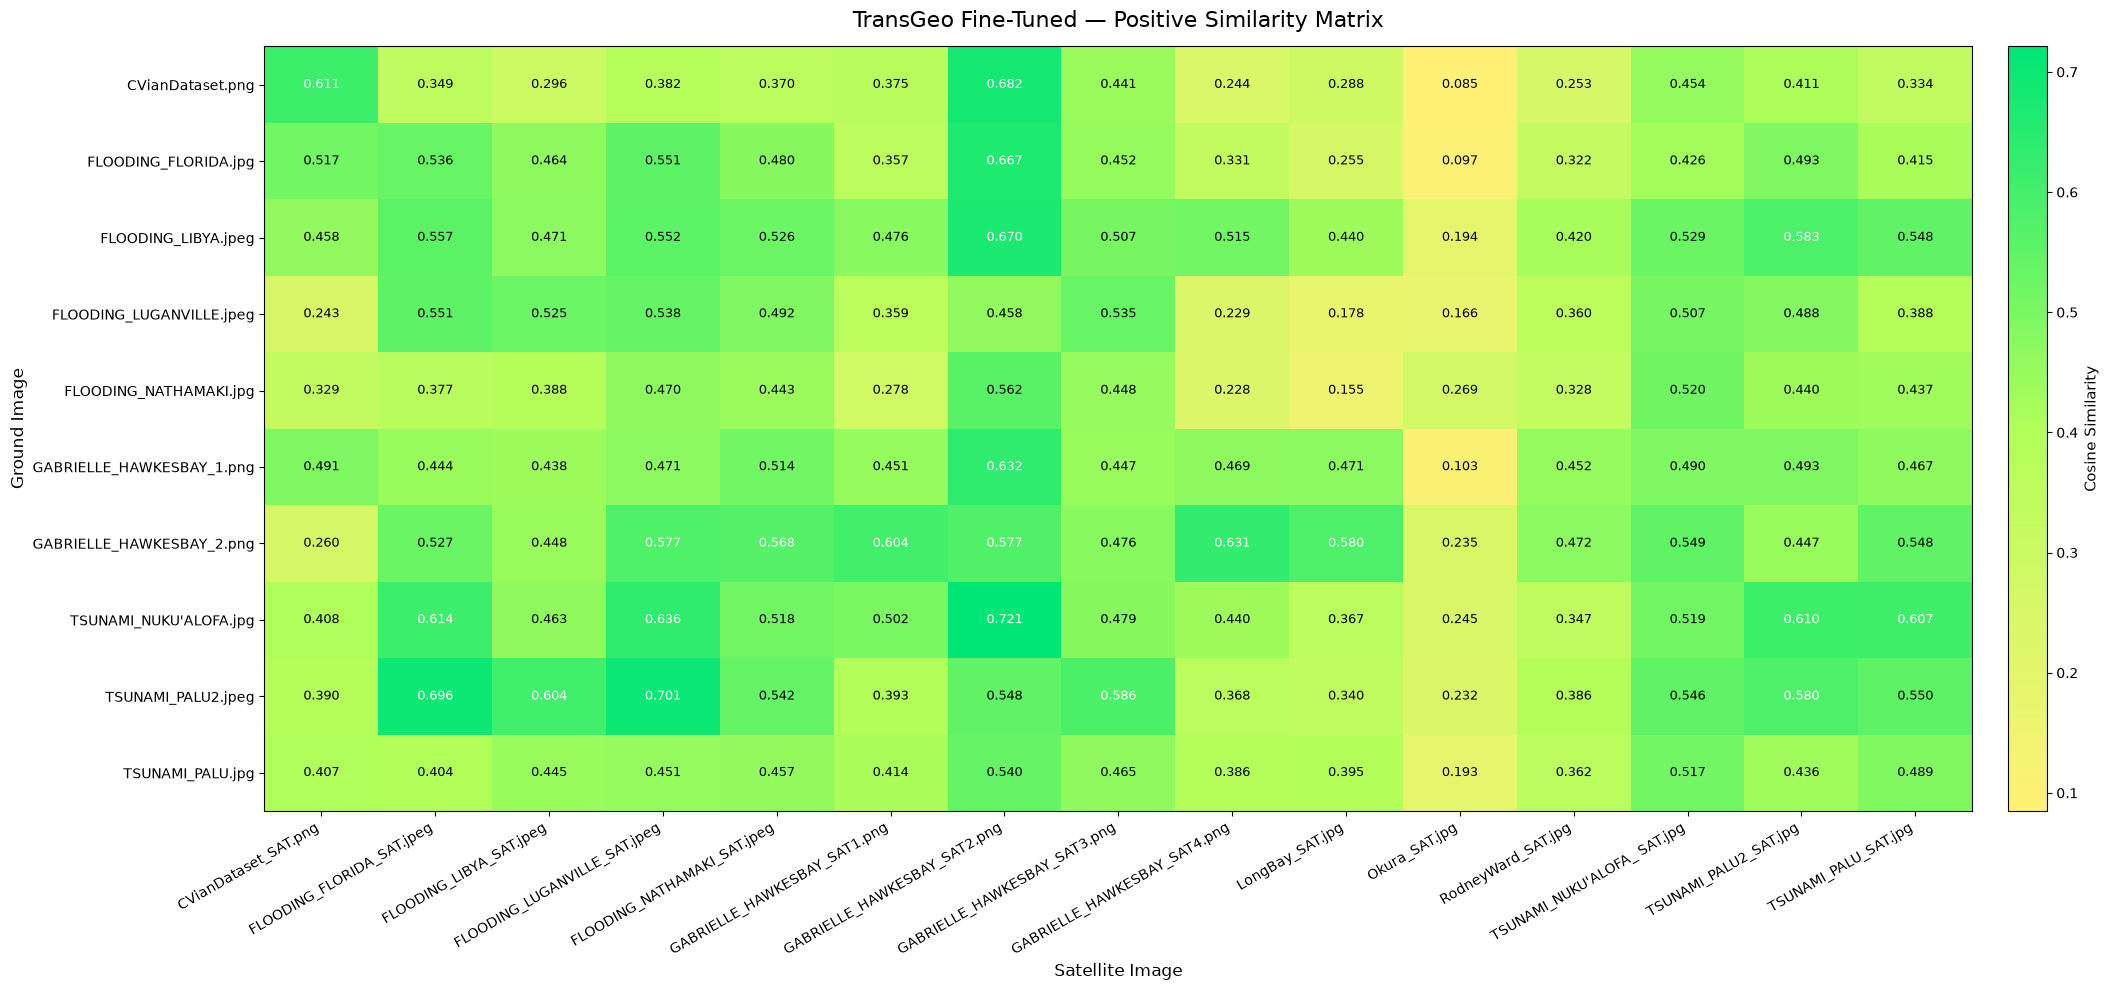

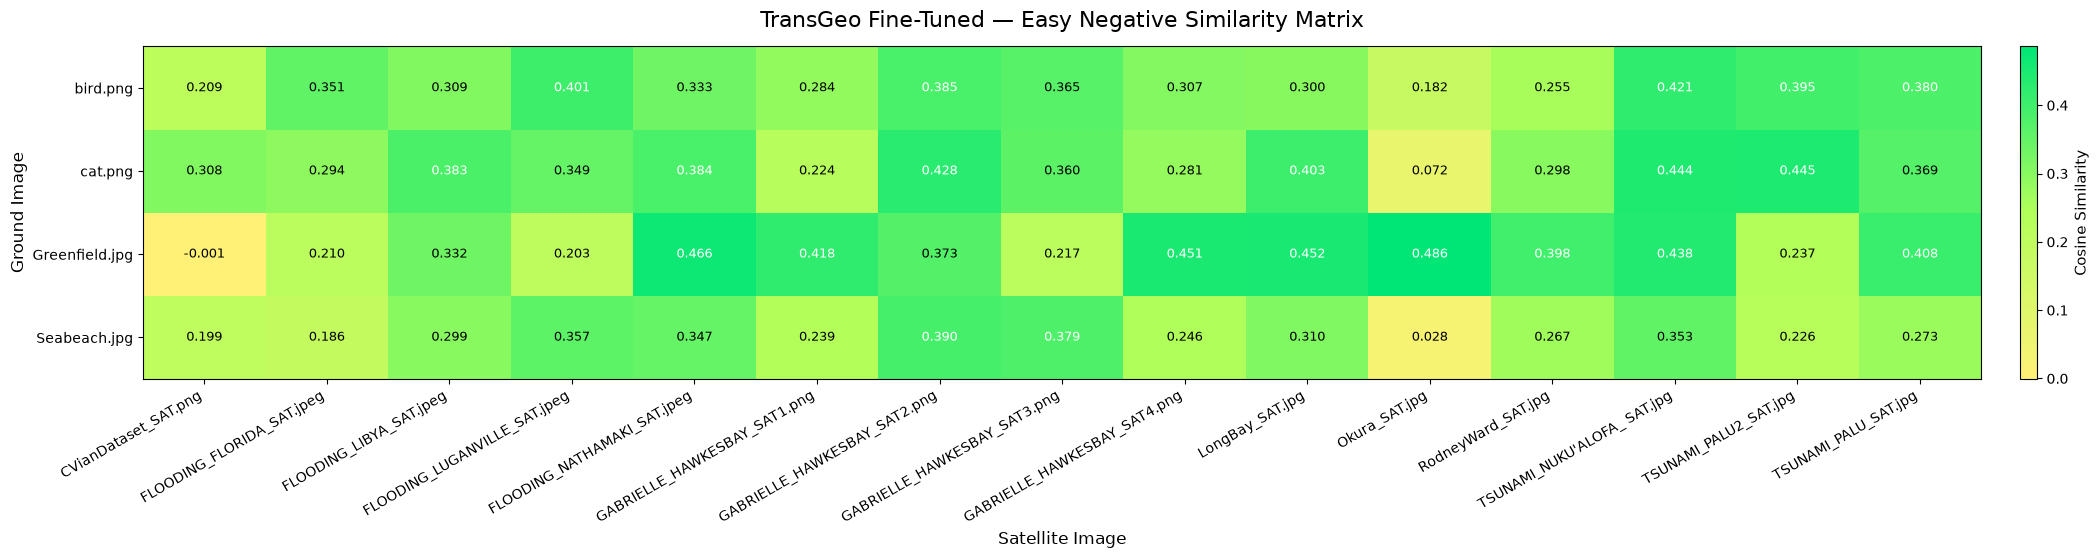

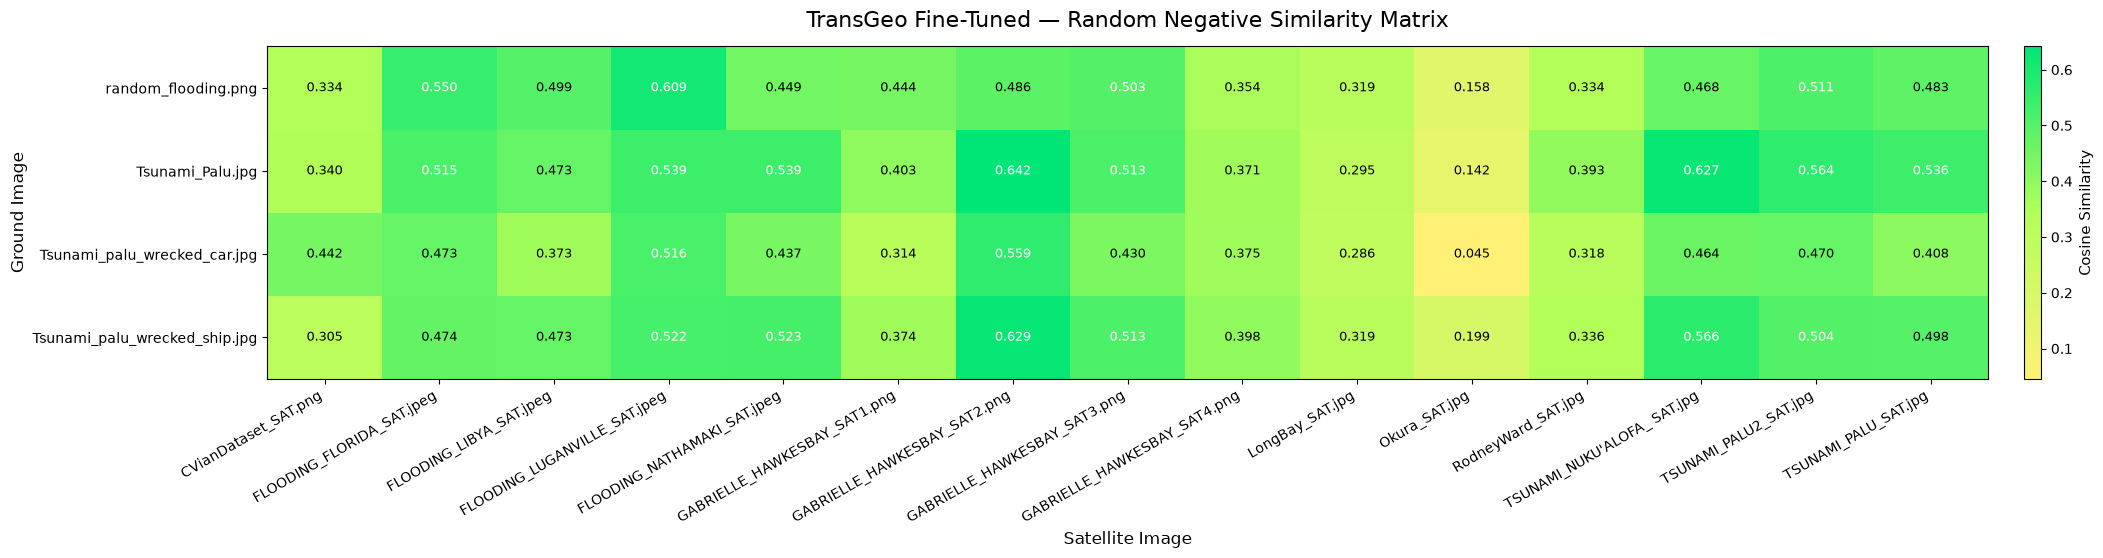

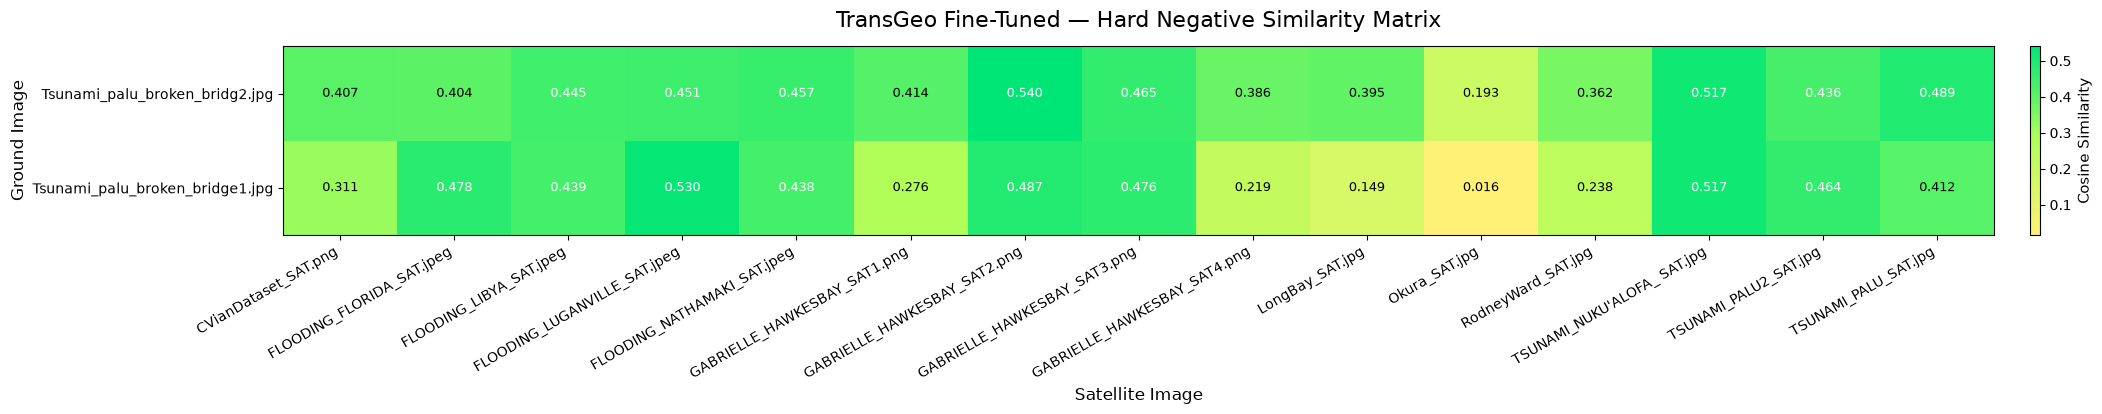

In [11]:
SIMILARITY_CMAP = LinearSegmentedColormap.from_list(
    "transgeo_similarity",
    ["#fff176", "#b2ff59", "#00e676"],
)


def plot_similarity_matrix(raw_df, query_type):
    subset = raw_df[raw_df["query_type"] == query_type].copy()

    if subset.empty:
        print("No rows found for:", query_type)
        return

    ordered_rows = query_inventory[
        query_inventory["query_type"] == query_type
    ]["ground_image"].tolist()

    ordered_cols = [path.name for path in satellite_files]

    matrix = subset.pivot(
        index="ground_image",
        columns="satellite_image",
        values="cosine_similarity",
    )

    matrix = matrix.reindex(
        index=ordered_rows,
        columns=ordered_cols,
    )

    values = matrix.values.astype(float)
    n_rows, n_cols = matrix.shape

    fig_width = max(11, 1.15 * n_cols + 4)
    fig_height = max(4, 0.72 * n_rows + 2.8)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    image = ax.imshow(
        values,
        cmap=SIMILARITY_CMAP,
        aspect="auto",
    )

    ax.set_xticks(range(n_cols))
    ax.set_xticklabels(
        matrix.columns,
        rotation=30,
        ha="right",
        fontsize=10,
    )

    ax.set_yticks(range(n_rows))
    ax.set_yticklabels(matrix.index, fontsize=10)

    ax.set_xlabel("Satellite Image", fontsize=12)
    ax.set_ylabel("Ground Image", fontsize=12)
    ax.set_title(
        f"{MODEL_LABEL} — {query_type} Similarity Matrix",
        fontsize=16,
        pad=14,
    )

    max_value = np.nanmax(values) if values.size else 1.0

    for row in range(n_rows):
        for column in range(n_cols):
            value = values[row, column]
            text_color = "white" if value > 0.78 * max_value else "black"

            ax.text(
                column,
                row,
                f"{value:.3f}",
                ha="center",
                va="center",
                fontsize=9,
                color=text_color,
            )

    colorbar = fig.colorbar(
        image,
        ax=ax,
        fraction=0.035,
        pad=0.02,
    )
    colorbar.set_label("Cosine Similarity", fontsize=11)

    plt.tight_layout()
    plt.show()


for query_type in QUERY_TYPE_ORDER:
    plot_similarity_matrix(similarity_raw, query_type)

# 9. Thresholded pair classification

Decision rule:

`cosine similarity > 0.50 → predicted match`

For the Positive folder, filename matching supplies the actual positive pair(s).

For Easy / Random / Hard Negative folders, every satellite comparison is an actual negative.

In [12]:
classified_rows = []

for _, row in similarity_raw.iterrows():
    query_type = row["query_type"]
    ground_image = row["ground_image"]
    satellite_image = row["satellite_image"]
    cosine_similarity = float(row["cosine_similarity"])

    predicted_positive = cosine_similarity > COSINE_THRESHOLD

    if query_type == "Positive":
        actual_positive_satellites = infer_positive_satellites(ground_image)
        actual_positive = satellite_image in actual_positive_satellites
    else:
        actual_positive_satellites = []
        actual_positive = False

    if actual_positive and predicted_positive:
        outcome = "TP"
    elif actual_positive and not predicted_positive:
        outcome = "FN"
    elif (not actual_positive) and predicted_positive:
        outcome = "FP"
    else:
        outcome = "TN"

    classified_rows.append({
        "query_type": query_type,
        "ground_image": ground_image,
        "satellite_image": satellite_image,
        "cosine_similarity": cosine_similarity,
        "predicted_positive": predicted_positive,
        "actual_positive": actual_positive,
        "outcome": outcome,
        "actual_positive_satellites": ", ".join(actual_positive_satellites),
    })

classified_pairs = pd.DataFrame(classified_rows)
display(classified_pairs.head())

,query_type,ground_image,satellite_image,cosine_similarity,predicted_positive,actual_positive,outcome,actual_positive_satellites
0,Positive,CVianDataset.png,CVianDataset_SAT.png,0.611328,True,True,TP,CVianDataset_SAT.png
1,Positive,CVianDataset.png,FLOODING_FLORIDA_SAT.jpeg,0.348633,False,False,TN,CVianDataset_SAT.png
2,Positive,CVianDataset.png,FLOODING_LIBYA_SAT.jpeg,0.296143,False,False,TN,CVianDataset_SAT.png
3,Positive,CVianDataset.png,FLOODING_LUGANVILLE_SAT.jpeg,0.381836,False,False,TN,CVianDataset_SAT.png
4,Positive,CVianDataset.png,FLOODING_NATHAMAKI_SAT.jpeg,0.369873,False,False,TN,CVianDataset_SAT.png


# 10. Positive confusion matrix

The Positive set uses the matched filename relation as ground truth.

Precision is also shown:

`Precision = TP / (TP + FP)`

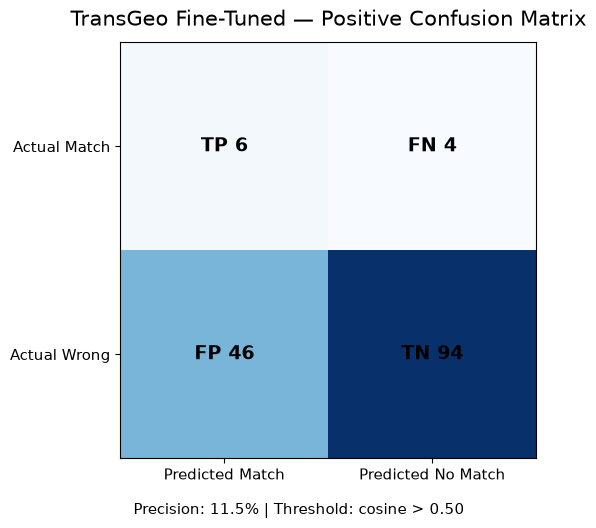

,TP,FP,TN,FN,Precision
0,6,46,94,4,0.115385


In [13]:
positive_pairs = classified_pairs[
    classified_pairs["query_type"] == "Positive"
].copy()

TP = int((positive_pairs["outcome"] == "TP").sum())
FP = int((positive_pairs["outcome"] == "FP").sum())
TN = int((positive_pairs["outcome"] == "TN").sum())
FN = int((positive_pairs["outcome"] == "FN").sum())

precision = TP / (TP + FP) if (TP + FP) > 0 else np.nan

confusion_matrix = np.array([
    [TP, FN],
    [FP, TN],
])

fig, ax = plt.subplots(figsize=(6.6, 5.3))
ax.imshow(confusion_matrix, cmap="Blues")

ax.set_xticks([0, 1])
ax.set_xticklabels(
    ["Predicted Match", "Predicted No Match"],
    fontsize=11,
)

ax.set_yticks([0, 1])
ax.set_yticklabels(
    ["Actual Match", "Actual Wrong"],
    fontsize=11,
)

cell_labels = np.array([
    ["TP", "FN"],
    ["FP", "TN"],
])

for row in range(2):
    for column in range(2):
        label_text = (
            cell_labels[row, column]
            + " "
            + str(int(confusion_matrix[row, column]))
        )

        ax.text(
            column,
            row,
            label_text,
            ha="center",
            va="center",
            fontsize=14,
            weight="bold",
        )

precision_text = (
    "N/A"
    if pd.isna(precision)
    else f"{precision * 100:.1f}%"
)

ax.set_title(
    f"{MODEL_LABEL} — Positive Confusion Matrix",
    fontsize=15,
    pad=12,
)

fig.text(
    0.5,
    0.02,
    f"Precision: {precision_text} | Threshold: cosine > {COSINE_THRESHOLD:.2f}",
    ha="center",
    fontsize=11,
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

positive_summary = pd.DataFrame([{
    "TP": TP,
    "FP": FP,
    "TN": TN,
    "FN": FN,
    "Precision": precision,
}])

display(positive_summary)

# 11. Negative FPR table

For each negative category:

`FPR = FP / (FP + TN)`

Lower is better.

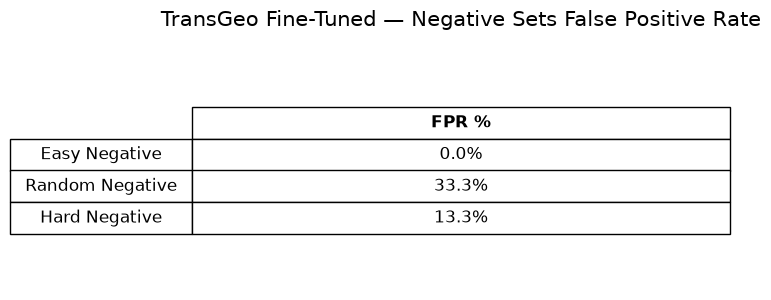

,Query Type,FPR
0,Easy Negative,0.000000
1,Random Negative,0.333333
2,Hard Negative,0.133333


In [14]:
negative_types = [
    "Easy Negative",
    "Random Negative",
    "Hard Negative",
]

fpr_rows = []

for query_type in negative_types:
    subset = classified_pairs[
        classified_pairs["query_type"] == query_type
    ]

    false_positive_count = int(
        (subset["outcome"] == "FP").sum()
    )

    true_negative_count = int(
        (subset["outcome"] == "TN").sum()
    )

    denominator = false_positive_count + true_negative_count

    fpr = (
        false_positive_count / denominator
        if denominator > 0
        else np.nan
    )

    fpr_rows.append({
        "Query Type": query_type,
        "FPR": fpr,
    })

negative_fpr = pd.DataFrame(fpr_rows)

table_text = []

for _, row in negative_fpr.iterrows():
    fpr_text = (
        "N/A"
        if pd.isna(row["FPR"])
        else f"{row['FPR'] * 100:.1f}%"
    )

    table_text.append([fpr_text])

fig, ax = plt.subplots(figsize=(7.5, 3.1))
ax.axis("off")

table = ax.table(
    cellText=table_text,
    rowLabels=negative_fpr["Query Type"].tolist(),
    colLabels=["FPR %"],
    cellLoc="center",
    rowLoc="center",
    loc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.0, 1.9)
table[0, 0].set_text_props(weight="bold")

ax.set_title(
    f"{MODEL_LABEL} — Negative Sets False Positive Rate",
    fontsize=15,
    pad=18,
)

plt.tight_layout()
plt.show()

display(negative_fpr)

# 12. Optional: inspect all false-positive pairs

This is useful when a negative category has a high FPR and you want to see exactly which ground/satellite combinations crossed the threshold.

In [15]:
false_positive_pairs = classified_pairs[
    classified_pairs["outcome"] == "FP"
].copy()

false_positive_pairs = false_positive_pairs.sort_values(
    ["query_type", "cosine_similarity"],
    ascending=[True, False],
)

display(
    false_positive_pairs[
        [
            "query_type",
            "ground_image",
            "satellite_image",
            "cosine_similarity",
        ]
    ]
)

,query_type,ground_image,satellite_image,cosine_similarity
276,Hard Negative,Tsunami_palu_broken_bridg2.jpg,GABRIELLE_HAWKESBAY_SAT2.png,0.540039
288,Hard Negative,Tsunami_palu_broken_bridge1.jpg,FLOODING_LUGANVILLE_SAT.jpeg,0.530273
297,Hard Negative,Tsunami_palu_broken_bridge1.jpg,TSUNAMI_NUKU'ALOFA_ SAT.jpg,0.517090
282,Hard Negative,Tsunami_palu_broken_bridg2.jpg,TSUNAMI_NUKU'ALOFA_ SAT.jpg,0.516602
111,Positive,TSUNAMI_NUKU'ALOFA.jpg,GABRIELLE_HAWKESBAY_SAT2.png,0.721191
...,...,...,...,...
232,Random Negative,Tsunami_Palu.jpg,GABRIELLE_HAWKESBAY_SAT3.png,0.512695
262,Random Negative,Tsunami_palu_wrecked_ship.jpg,GABRIELLE_HAWKESBAY_SAT3.png,0.512695
223,Random Negative,random_flooding.png,TSUNAMI_PALU2_SAT.jpg,0.511230
268,Random Negative,Tsunami_palu_wrecked_ship.jpg,TSUNAMI_PALU2_SAT.jpg,0.503906
